# Global Solution 2026.2 - CitizenTech: Previsão de lotação nas estações do Metrô de São Paulo

**Disciplina:** Inteligência Artificial & Machine Learning

**Pergunta de ML:** dá para prever quantas pessoas vão entrar em cada estação do Metrô de São Paulo em um determinado dia, usando o calendário e o histórico recente da própria estação?

Se der, essa previsão pode virar um aviso simples para o cidadão ("amanhã a estação Sé deve estar mais cheia que o normal") e ajudar quem depende do metrô a escolher melhor o horário ou a estação de embarque.

**Modelo escolhido:** Random Forest Regressor.

## 1. Importação das bibliotecas

- `pandas` e `numpy`: organizar e calcular os dados.
- `matplotlib`: gráficos.
- `scikit-learn`: modelo Random Forest, divisão dos dados, validação cruzada e métricas.

In [1]:
import warnings
warnings.simplefilter("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, confusion_matrix

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 100
SEED = 42

## 2. Dados reais e públicos

Os dados são as **entradas diárias de passageiros por estação** das linhas operadas pela Companhia do Metropolitano de São Paulo (Linhas 1-Azul, 2-Verde, 3-Vermelha e 15-Prata).

- **Fonte original:** Portal da Transparência do Metrô SP, seção Demanda (https://transparencia.metrosp.com.br/dataset/demanda).
- **Arquivo usado:** como o portal estava fora do ar (em manutenção) quando fizemos o trabalho, baixamos o mesmo dado já organizado em CSV pelo projeto aberto `metrosp` (https://github.com/viniciusoike/metrosp), que junta os relatórios mensais do portal em um único arquivo.
- **Período:** 01/01/2020 a 30/09/2026.
- **Unidade:** a coluna `passengers` está em **milhares de passageiros** que entraram na estação no dia.

Mais detalhes estão em `dados/README.md`. Não usamos nenhum dado pessoal, só totais por estação.

In [2]:
df_raw = pd.read_csv("dados/entradas_diarias_estacoes_metro_sp.csv", parse_dates=["date"])

print("Formato do dataset:", df_raw.shape)
df_raw.head()

Formato do dataset: (160646, 6)


,date,year,line_number,station_code,station_name,passengers
0,2020-01-01,2020,1,anr,Ana Rosa,3.4
1,2020-01-01,2020,1,arv,Praça da Árvore,2.7
2,2020-01-01,2020,1,bto,São Bento,2.6
3,2020-01-01,2020,1,cdu,Carandiru,2.1
4,2020-01-01,2020,1,con,Conceição,6.0


In [3]:
print("Período:", df_raw["date"].min().date(), "até", df_raw["date"].max().date())
print("Quantidade de estações:", df_raw["station_name"].nunique())
print()
print("Registros por linha:")
print(df_raw["line_number"].value_counts().sort_index())
print()
print("Valores nulos por coluna:")
print(df_raw.isnull().sum())
print()
print("Linhas duplicadas (mesma data, linha e estação):",
      df_raw.duplicated(["date", "line_number", "station_code"]).sum())

Período: 2020-01-01 até 2026-09-30
Quantidade de estações: 62

Registros por linha:
line_number
1     56624
2     34483
3     44291
15    25248
Name: count, dtype: int64

Valores nulos por coluna:
date            0
year            0
line_number     0
station_code    0
station_name    0
passengers      0
dtype: int64

Linhas duplicadas (mesma data, linha e estação): 0


O dataset não tem valores nulos nem linhas duplicadas. Cada linha é um dia em uma estação. Estações de transferência (por exemplo, Sé, que atende as Linhas 1 e 3) aparecem uma vez para cada linha, por isso usamos a combinação linha + estação como identificador.

## 3. Análise exploratória

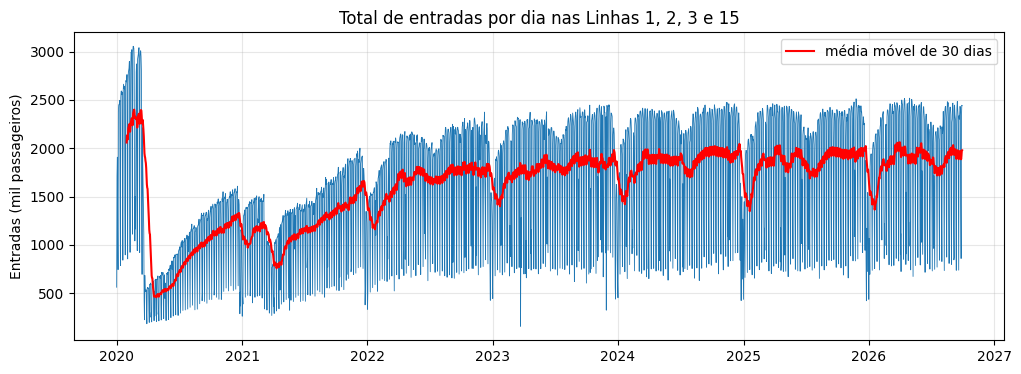

In [4]:
total_dia = df_raw.groupby("date")["passengers"].sum()

plt.figure(figsize=(12, 4))
plt.plot(total_dia.index, total_dia.values, linewidth=0.6)
plt.plot(total_dia.rolling(30).mean(), color="red", label="média móvel de 30 dias")
plt.title("Total de entradas por dia nas Linhas 1, 2, 3 e 15")
plt.ylabel("Entradas (mil passageiros)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Dá para ver claramente a queda causada pela pandemia em 2020 e 2021. A partir de 2022 a demanda volta para um patamar mais estável. Como 2020 e 2021 foram anos fora do normal, vamos **treinar e testar o modelo só com dados de 2022 em diante**. Os dados de 2021 ainda serão usados apenas para calcular o histórico das primeiras semanas de 2022.

Também aparece o padrão semanal (os "dentes" do gráfico): dias úteis cheios e fins de semana bem mais vazios.

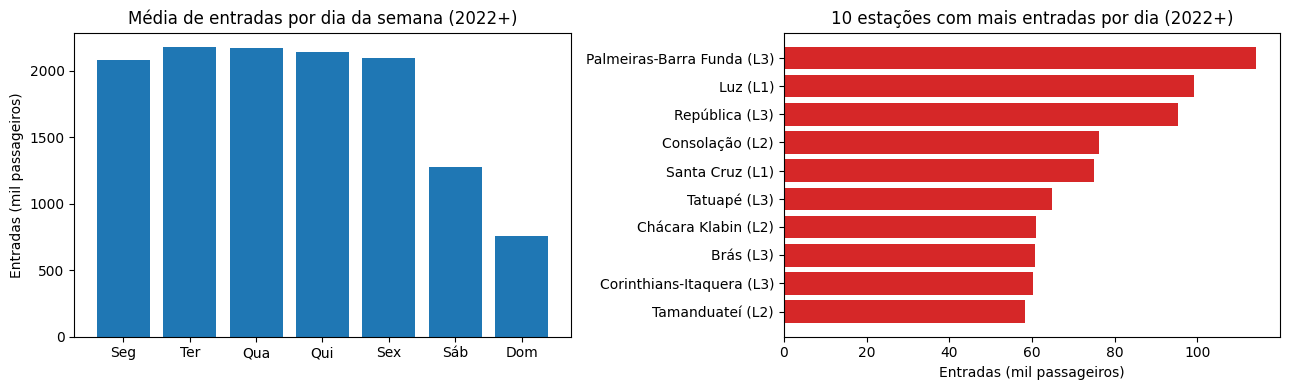

In [5]:
df_raw["dia_semana"] = df_raw["date"].dt.dayofweek
nomes_dias = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]

pos2022 = df_raw[df_raw["date"] >= "2022-01-01"]
media_dia = pos2022.groupby(["date", "dia_semana"])["passengers"].sum().groupby("dia_semana").mean()

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].bar(nomes_dias, media_dia.values, color="tab:blue")
axs[0].set_title("Média de entradas por dia da semana (2022+)")
axs[0].set_ylabel("Entradas (mil passageiros)")

top = (pos2022.groupby(["line_number", "station_name"])["passengers"].mean()
       .sort_values(ascending=False).head(10))
rotulos = [f"{nome} (L{linha})" for linha, nome in top.index]
axs[1].barh(rotulos[::-1], top.values[::-1], color="tab:red")
axs[1].set_title("10 estações com mais entradas por dia (2022+)")
axs[1].set_xlabel("Entradas (mil passageiros)")
plt.tight_layout()
plt.show()

- De segunda a sexta o movimento é parecido. Sábado cai bastante e domingo é o dia mais vazio.
- As estações com mais entradas são pontos de integração com trem, ônibus ou outras linhas (Palmeiras-Barra Funda, Luz, República, Consolação, Santa Cruz, Tatuapé etc.). A diferença entre estações é enorme: algumas recebem mais de 100 mil entradas por dia e outras menos de 5 mil. Ou seja, o volume depende muito de **qual estação** é, e o modelo precisa saber isso.

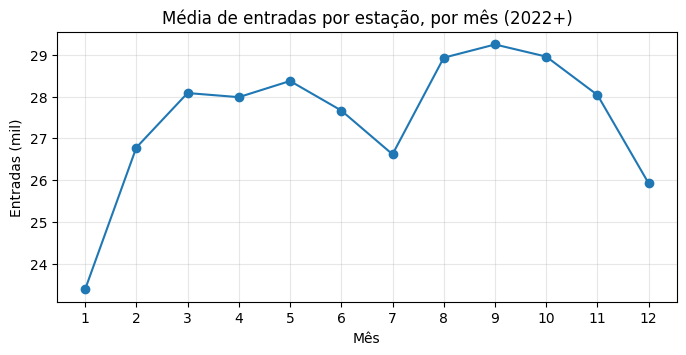

In [6]:
media_mes = pos2022.groupby(pos2022["date"].dt.month)["passengers"].mean()

plt.figure(figsize=(8, 3.5))
plt.plot(media_mes.index, media_mes.values, marker="o")
plt.xticks(range(1, 13))
plt.title("Média de entradas por estação, por mês (2022+)")
plt.xlabel("Mês")
plt.ylabel("Entradas (mil)")
plt.grid(alpha=0.3)
plt.show()

Janeiro, julho e dezembro têm menos movimento (férias escolares e fim de ano). Então o mês também é uma informação útil para o modelo.

## 4. Preparação dos dados

### 4.1 Feriados

Feriado muda muito o movimento do metrô. Montamos uma lista com os feriados nacionais, o feriado estadual de 9 de julho, o aniversário de São Paulo (25/01), a Consciência Negra (20/11) e o Carnaval (segunda e terça). As datas móveis (Carnaval, Sexta-feira Santa e Corpus Christi) foram calculadas a partir da Páscoa de cada ano.

In [7]:
pascoa = {2021: "2021-04-04", 2022: "2022-04-17", 2023: "2023-04-09",
          2024: "2024-03-31", 2025: "2025-04-20", 2026: "2026-04-05"}
fixos = ["01-01", "01-25", "04-21", "05-01", "07-09", "09-07", "10-12", "11-02", "11-15", "11-20", "12-25"]

feriados = []
for ano, data_pascoa in pascoa.items():
    p = pd.Timestamp(data_pascoa)
    feriados += [pd.Timestamp(f"{ano}-{f}") for f in fixos]
    feriados += [p - pd.Timedelta(days=48),  # segunda de Carnaval
                 p - pd.Timedelta(days=47),  # terça de Carnaval
                 p - pd.Timedelta(days=2),   # Sexta-feira Santa
                 p + pd.Timedelta(days=60)]  # Corpus Christi
feriados = pd.to_datetime(sorted(set(feriados)))
print("Total de feriados considerados:", len(feriados))

Total de feriados considerados: 90


### 4.2 Criação das variáveis (features)

Para cada estação e dia, criamos:

| Variável | Significado |
|---|---|
| `linha` | número da linha (1, 2, 3 ou 15) |
| `estacao_id` | código numérico da estação |
| `dia_semana` | 0 = segunda ... 6 = domingo |
| `mes`, `dia_mes`, `ano` | informações do calendário |
| `feriado` | 1 se o dia é feriado |
| `vespera_feriado` | 1 se o dia seguinte é feriado (muita gente viaja) |
| `emenda` | 1 se é um dia útil "espremido" entre feriado e fim de semana (ex.: sexta depois de feriado na quinta) ou a Quarta-feira de Cinzas |
| `feriado_semana_passada` | 1 se o dia de 7 dias atrás foi feriado (avisa o modelo que o `lag_7` está "baixo demais") |
| `lag_7` | entradas da mesma estação no mesmo dia da semana anterior |
| `lag_14` | entradas da mesma estação duas semanas antes |
| `media_4_semanas` | média das entradas da estação nas últimas 4 semanas, no mesmo dia da semana |

As variáveis `lag` usam **só dados do passado**: para prever o dia D, usamos o que aconteceu em D-7, D-14, D-21 e D-28. Isso é realista, porque no dia da previsão esses valores já são conhecidos. O alvo (`entradas`) nunca entra como variável de entrada.

In [8]:
df = df_raw.rename(columns={"date": "data", "line_number": "linha",
                            "station_name": "estacao", "passengers": "entradas"})
df["chave"] = df["linha"].astype(str) + "_" + df["station_code"]
df["estacao_id"] = df["chave"].astype("category").cat.codes

df["mes"] = df["data"].dt.month
df["dia_mes"] = df["data"].dt.day
df["ano"] = df["data"].dt.year
df["feriado"] = df["data"].isin(feriados).astype(int)
df["vespera_feriado"] = (df["data"] + pd.Timedelta(days=1)).isin(feriados).astype(int)

# emenda: dia útil entre um feriado e o fim de semana (ex.: sexta depois de feriado na quinta)
ontem_feriado = (df["data"] - pd.Timedelta(days=1)).isin(feriados)
amanha_feriado = (df["data"] + pd.Timedelta(days=1)).isin(feriados)
quartas_cinzas = [pd.Timestamp(p) - pd.Timedelta(days=46) for p in pascoa.values()]
df["emenda"] = (((df["dia_semana"] == 4) & ontem_feriado)
                | ((df["dia_semana"] == 0) & amanha_feriado)
                | df["data"].isin(quartas_cinzas)).astype(int)
df.loc[df["feriado"] == 1, "emenda"] = 0
df["feriado_semana_passada"] = (df["data"] - pd.Timedelta(days=7)).isin(feriados).astype(int)

# histórico da própria estação (mesmo dia da semana nas semanas anteriores)
base = df[["chave", "data", "entradas"]]
for semanas in [1, 2, 3, 4]:
    aux = base.copy()
    aux["data"] = aux["data"] + pd.Timedelta(days=7 * semanas)
    aux = aux.rename(columns={"entradas": f"lag_{7 * semanas}"})
    df = df.merge(aux, on=["chave", "data"], how="left")

df["media_4_semanas"] = df[["lag_7", "lag_14", "lag_21", "lag_28"]].mean(axis=1)

df[["data", "estacao", "linha", "dia_semana", "feriado", "lag_7", "media_4_semanas", "entradas"]].head(10)

,data,estacao,linha,dia_semana,feriado,lag_7,media_4_semanas,entradas
0,2020-01-01,Ana Rosa,1,2,0,NaN,NaN,3.4
1,2020-01-01,Praça da Árvore,1,2,0,NaN,NaN,2.7
2,2020-01-01,São Bento,1,2,0,NaN,NaN,2.6
3,2020-01-01,Carandiru,1,2,0,NaN,NaN,2.1
4,2020-01-01,Conceição,1,2,0,NaN,NaN,6.0
5,2020-01-01,Jabaquara,1,2,0,NaN,NaN,59.3
6,2020-01-01,Jardim São Paulo-Ayrton Senna,1,2,0,NaN,NaN,1.7
7,2020-01-01,São Joaquim,1,2,0,NaN,NaN,4.1
8,2020-01-01,São Judas,1,2,0,NaN,NaN,3.7
9,2020-01-01,Japão-Liberdade,1,2,0,NaN,NaN,3.4


### 4.3 Limpeza

- Ficamos só com 2022 em diante (fora do período da pandemia).
- Removemos linhas sem histórico completo (por exemplo, uma estação recém-inaugurada ainda não tem 4 semanas anteriores).
- Removemos os poucos dias com 0 entradas, que indicam estação fechada (greve, obra ou falha) e não um dia normal de operação.

In [9]:
antes = len(df)
df = df[df["data"] >= "2022-01-01"]
df = df.dropna(subset=["lag_7", "lag_14", "lag_21", "lag_28"])
df = df[df["entradas"] > 0]
print("Linhas antes:", antes, "| depois da limpeza:", len(df))

Linhas antes: 160646 | depois da limpeza: 113325


### 4.4 Divisão em treino e teste

Como é um problema de **previsão no tempo**, não faz sentido sortear as linhas aleatoriamente: o modelo estaria "vendo o futuro" durante o treino. Por isso a divisão foi feita pela data:

- **Treino:** 2022 a 2025 (4 anos).
- **Teste:** janeiro a setembro de 2026 (dados que o modelo nunca viu).

Isso simula o uso real: treinamos com o passado e prevemos o que vem depois.

In [10]:
features = ['linha', 'estacao_id', 'dia_semana', 'mes', 'dia_mes', 'ano', 'feriado', 'vespera_feriado', 'emenda', 'feriado_semana_passada', 'lag_7', 'lag_14', 'media_4_semanas']
alvo = "entradas"

df = df.sort_values("data").reset_index(drop=True)
treino = df[df["data"] < "2026-01-01"]
teste = df[df["data"] >= "2026-01-01"]

X_train, y_train = treino[features], treino[alvo]
X_test, y_test = teste[features], teste[alvo]

print("Treino:", X_train.shape, "|", treino["data"].min().date(), "a", treino["data"].max().date())
print("Teste: ", X_test.shape, "|", teste["data"].min().date(), "a", teste["data"].max().date())
print(f"Proporção de teste: {len(teste) / len(df):.1%}")

Treino: (95307, 13) | 2022-01-01 a 2025-12-31
Teste:  (18018, 13) | 2026-01-01 a 2026-09-30
Proporção de teste: 15.9%


## 5. Escolha do modelo

Escolhemos o **Random Forest Regressor** porque:

- o problema é de **regressão** (prever um número: quantas mil pessoas entram na estação);
- a relação entre as variáveis e o movimento não é linear (por exemplo, o efeito do feriado é diferente em uma estação de terminal rodoviário e em uma estação de bairro). Uma floresta de árvores capta essas interações sozinha;
- não precisa normalizar os dados e lida bem com variáveis como `estacao_id` codificadas como número;
- é menos propenso a overfitting do que uma árvore de decisão sozinha, porque faz a média de muitas árvores;
- mostra a **importância de cada variável**, o que ajuda a explicar o resultado para quem não é da área.

Antes do modelo, calculamos uma **linha de base** bem simples: "o movimento de hoje vai ser igual ao da semana passada" (`lag_7`). O Random Forest só vale a pena se for melhor que isso.

In [11]:
def metricas(y_real, y_prev):
    return {
        "MAE (mil)": mean_absolute_error(y_real, y_prev),
        "RMSE (mil)": np.sqrt(mean_squared_error(y_real, y_prev)),
        "R²": r2_score(y_real, y_prev),
        "Erro % médio": np.mean(np.abs(y_real - y_prev) / y_real) * 100,
    }

base_treino = metricas(y_train, X_train["lag_7"])
base_teste = metricas(y_test, X_test["lag_7"])
pd.DataFrame({"Treino": base_treino, "Teste": base_teste}).round(3)

,Treino,Teste
MAE (mil),2.925,3.133
RMSE (mil),7.913,8.292
R²,0.919,0.915
Erro % médio,16.546,14.330


A linha de base já é razoável porque o movimento do metrô é bem repetitivo de uma semana para a outra. O problema é que ela erra feio nos feriados e nas semanas depois deles (se a semana passada teve feriado, ela prevê um dia vazio). É isso que o modelo precisa melhorar.

## 6. Treino com diferentes hiperparâmetros

Testamos **12 combinações** de 3 hiperparâmetros do Random Forest:

| Hiperparâmetro | O que controla | Valores testados |
|---|---|---|
| `n_estimators` | quantidade de árvores na floresta | 50, 150 |
| `max_depth` | profundidade máxima de cada árvore | 8, 16, sem limite |
| `min_samples_leaf` | mínimo de exemplos em cada folha | 1, 10 |

A **validação cruzada foi feita só no conjunto de treino**, usando `TimeSeriesSplit` com 4 divisões. Ele respeita a ordem do tempo: em cada rodada treina com um período e valida no período seguinte, nunca o contrário. O conjunto de teste (2026) só é usado no final.

A métrica usada para escolher o melhor modelo foi o **MAE** (erro absoluto médio), porque é fácil de explicar: "em média o modelo erra X mil passageiros por estação por dia".

In [12]:
grade = {
    "n_estimators": [50, 150],
    "max_depth": [8, 16, None],
    "min_samples_leaf": [1, 10],
}

busca = GridSearchCV(
    RandomForestRegressor(random_state=SEED, n_jobs=-1, max_features=0.6),
    param_grid=grade,
    cv=TimeSeriesSplit(n_splits=4),
    scoring="neg_mean_absolute_error",
    return_train_score=True,
    n_jobs=1,
)
busca.fit(X_train, y_train)

print("Melhor combinação:", busca.best_params_)
print(f"MAE médio na validação: {-busca.best_score_:.3f} mil passageiros")

Melhor combinação: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 150}
MAE médio na validação: 1.702 mil passageiros


In [13]:
res = pd.DataFrame(busca.cv_results_)
tabela = pd.DataFrame({
    "n_estimators": res["param_n_estimators"],
    "max_depth": res["param_max_depth"].astype(str).replace("None", "sem limite"),
    "min_samples_leaf": res["param_min_samples_leaf"],
    "MAE treino (CV)": -res["mean_train_score"],
    "MAE validação (CV)": -res["mean_test_score"],
    "tempo de treino (s)": res["mean_fit_time"],
})
tabela["diferença"] = tabela["MAE validação (CV)"] - tabela["MAE treino (CV)"]
tabela = tabela.sort_values("MAE validação (CV)").reset_index(drop=True)
tabela.round(3)

,n_estimators,max_depth,min_samples_leaf,MAE treino (CV),MAE validação (CV),tempo de treino (s),diferença
0,150,sem limite,1,0.477,1.702,1.204,1.225
1,150,16,1,0.821,1.706,0.771,0.885
2,50,16,1,0.828,1.720,0.285,0.891
3,50,sem limite,1,0.495,1.724,0.431,1.230
4,150,sem limite,10,1.263,1.883,0.694,0.620
5,50,sem limite,10,1.268,1.885,0.279,0.617
6,150,16,10,1.292,1.886,0.663,0.593
7,50,16,10,1.297,1.893,0.251,0.595
8,150,8,1,1.616,2.042,0.417,0.426
9,50,8,1,1.618,2.045,0.171,0.427


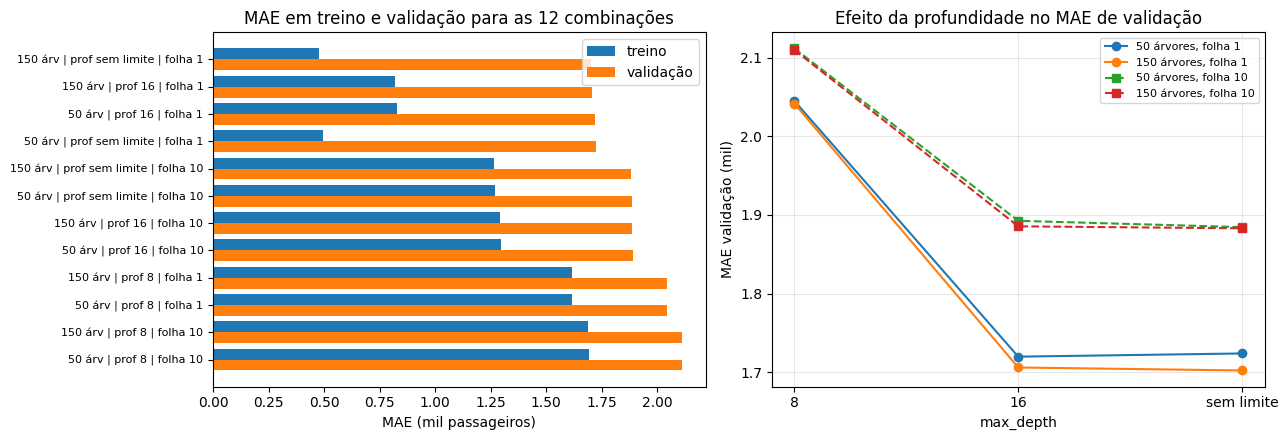

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))

rotulo = (tabela["n_estimators"].astype(str) + " árv | prof " + tabela["max_depth"]
          + " | folha " + tabela["min_samples_leaf"].astype(str))
ordem = np.arange(len(tabela))
axs[0].barh(ordem - 0.2, tabela["MAE treino (CV)"], height=0.4, label="treino")
axs[0].barh(ordem + 0.2, tabela["MAE validação (CV)"], height=0.4, label="validação")
axs[0].set_yticks(ordem)
axs[0].set_yticklabels(rotulo, fontsize=8)
axs[0].invert_yaxis()
axs[0].set_xlabel("MAE (mil passageiros)")
axs[0].set_title("MAE em treino e validação para as 12 combinações")
axs[0].legend()

for folha, estilo in [(1, "o-"), (10, "s--")]:
    for n_arv in [50, 150]:
        parte = tabela[(tabela["min_samples_leaf"] == folha) & (tabela["n_estimators"] == n_arv)]
        parte = parte.set_index("max_depth").loc[["8", "16", "sem limite"]]
        axs[1].plot(parte.index, parte["MAE validação (CV)"], estilo,
                    label=f"{n_arv} árvores, folha {folha}")
axs[1].set_title("Efeito da profundidade no MAE de validação")
axs[1].set_xlabel("max_depth")
axs[1].set_ylabel("MAE validação (mil)")
axs[1].legend(fontsize=8)
axs[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Leitura dos resultados da busca:**

- O hiperparâmetro que mais mudou o resultado foi o `max_depth`. Com profundidade 8 as árvores ficam simples demais: o erro é alto tanto no treino quanto na validação (**underfitting**).
- Sem limite de profundidade e com `min_samples_leaf=1`, o erro de **treino** fica muito baixo (cerca de 0,5 mil), mas o de **validação** fica em torno de 1,7 mil. Essa diferença entre treino e validação mostra que as árvores "decoram" parte dos dados de treino, ou seja, existe **overfitting**.
- Aumentar `min_samples_leaf` para 10 diminui bastante essa diferença (de ~1,2 para ~0,6), mas o erro de validação piora um pouco (de ~1,70 para ~1,88). Então, para este problema, a árvore mais detalhada ainda erra menos em dados novos, mesmo decorando um pouco o treino.
- `max_depth=16` e "sem limite" ficaram praticamente empatados na validação.
- Passar de 50 para 150 árvores melhora pouco o erro e quase triplica o tempo de treino.

Como a escolha é feita pelo erro na **validação** (e não no treino), o GridSearchCV escolheu a combinação com menor MAE de validação.

## 7. Modelo final: resultados em treino e teste

O `GridSearchCV` já retreina a melhor combinação usando todo o conjunto de treino. Agora avaliamos esse modelo no treino e no teste (2026), lado a lado, junto com a linha de base.

In [15]:
modelo = busca.best_estimator_
prev_treino = modelo.predict(X_train)
prev_teste = modelo.predict(X_test)

comparacao = pd.DataFrame({
    "Base (semana passada) - teste": base_teste,
    "Random Forest - treino": metricas(y_train, prev_treino),
    "Random Forest - teste": metricas(y_test, prev_teste),
}).round(3)
comparacao

,Base (semana passada) - teste,Random Forest - treino,Random Forest - teste
MAE (mil),3.133,0.471,1.441
RMSE (mil),8.292,1.081,3.159
R²,0.915,0.998,0.988
Erro % médio,14.330,2.550,6.204


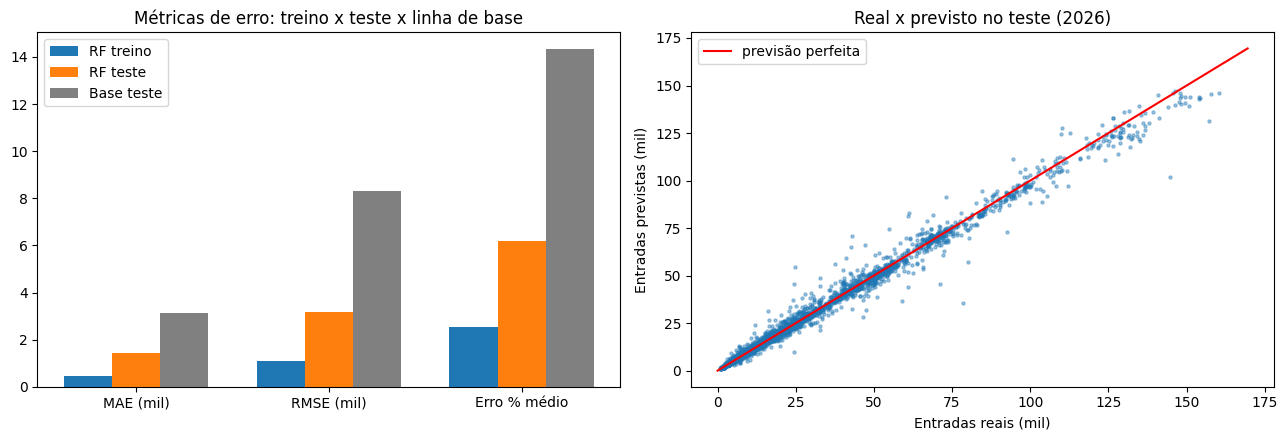

In [16]:
nomes = ["MAE (mil)", "RMSE (mil)", "Erro % médio"]
x = np.arange(len(nomes))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
axs[0].bar(x - 0.25, comparacao.loc[nomes, "Random Forest - treino"], 0.25, label="RF treino")
axs[0].bar(x, comparacao.loc[nomes, "Random Forest - teste"], 0.25, label="RF teste")
axs[0].bar(x + 0.25, comparacao.loc[nomes, "Base (semana passada) - teste"], 0.25, label="Base teste", color="gray")
axs[0].set_xticks(x)
axs[0].set_xticklabels(nomes)
axs[0].set_title("Métricas de erro: treino x teste x linha de base")
axs[0].legend()

amostra = teste.sample(4000, random_state=SEED).index
axs[1].scatter(y_test.loc[amostra], prev_teste[teste.index.get_indexer(amostra)], s=5, alpha=0.4)
lim = [0, y_test.max()]
axs[1].plot(lim, lim, color="red", label="previsão perfeita")
axs[1].set_xlabel("Entradas reais (mil)")
axs[1].set_ylabel("Entradas previstas (mil)")
axs[1].set_title("Real x previsto no teste (2026)")
axs[1].legend()
plt.tight_layout()
plt.show()

**Overfitting:** o erro no treino (MAE ~0,5 mil, erro médio ~2,5%) é bem menor que no teste (MAE ~1,4 mil, erro médio ~6%). Isso confirma o que vimos na busca: o Random Forest sem limite de profundidade se ajusta demais ao treino. Mesmo assim, o resultado no teste continua bom: R² de ~0,99 em 2026, um período que o modelo nunca viu, e o erro no teste ficou parecido com o erro da validação cruzada (~1,7 mil). Ou seja, existe overfitting, mas ele **não atrapalha a previsão em dados novos**. Se quiséssemos um modelo mais "equilibrado", poderíamos usar `min_samples_leaf=10`, aceitando um erro um pouco maior.

O Random Forest também ficou bem melhor que a linha de base "igual à semana passada": o erro médio caiu de ~3,1 mil para ~1,4 mil passageiros por estação (mais da metade), principalmente porque ele sabe quando é feriado, emenda ou quando a semana anterior teve feriado.

No gráfico de dispersão, os pontos ficam colados na linha vermelha. Os pontos mais longe dela são dias atípicos (greves, falhas, eventos), que nenhuma variável do modelo consegue explicar.

### 7.1 Exemplo: previsão para uma estação ao longo de 2026

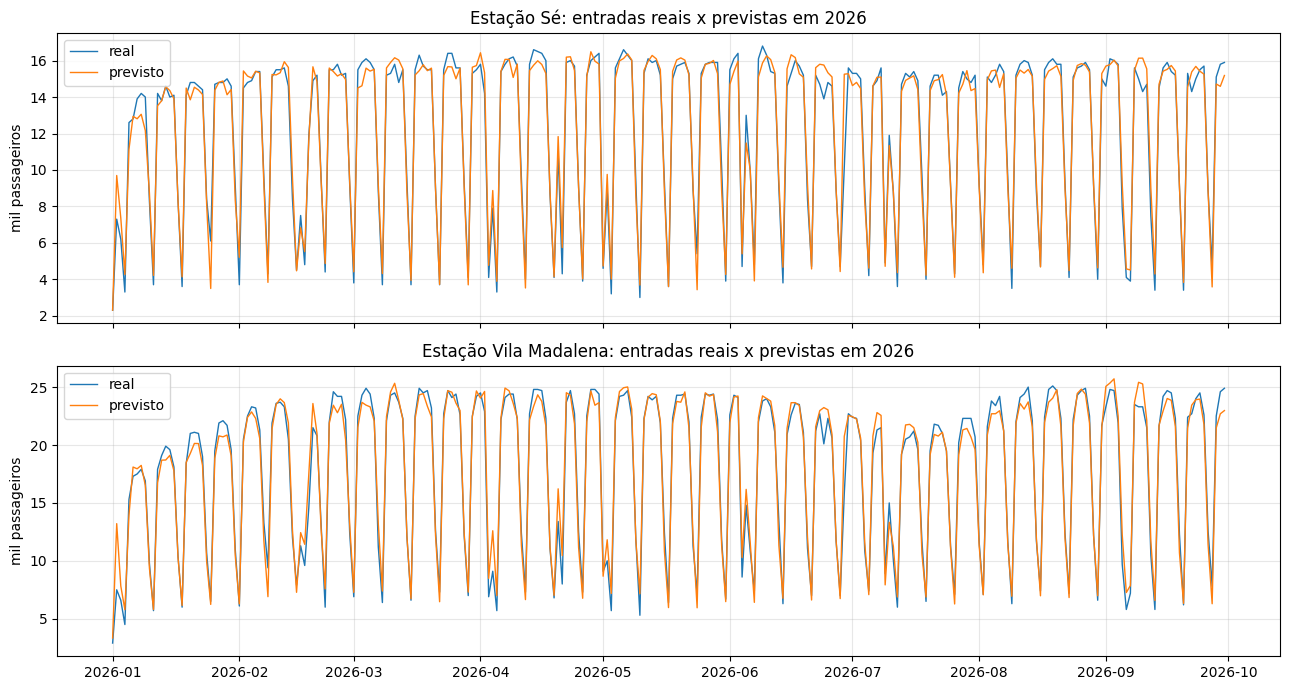

In [17]:
fig, axs = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, nome in zip(axs, ["Sé", "Vila Madalena"]):
    filtro = (teste["estacao"] == nome) & (teste["linha"] == (1 if nome == "Sé" else 2))
    serie = teste[filtro]
    ax.plot(serie["data"], serie["entradas"], label="real", linewidth=1)
    ax.plot(serie["data"], prev_teste[teste.index.get_indexer(serie.index)], label="previsto", linewidth=1)
    ax.set_title(f"Estação {nome}: entradas reais x previstas em 2026")
    ax.set_ylabel("mil passageiros")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

O modelo acompanha o padrão semanal e também as quedas de feriado (Carnaval, Sexta-feira Santa, Corpus Christi, 9 de julho). Isso é exatamente a informação que um cidadão precisaria para saber se a estação vai estar mais cheia ou mais vazia do que o normal.

### 7.2 Importância das variáveis

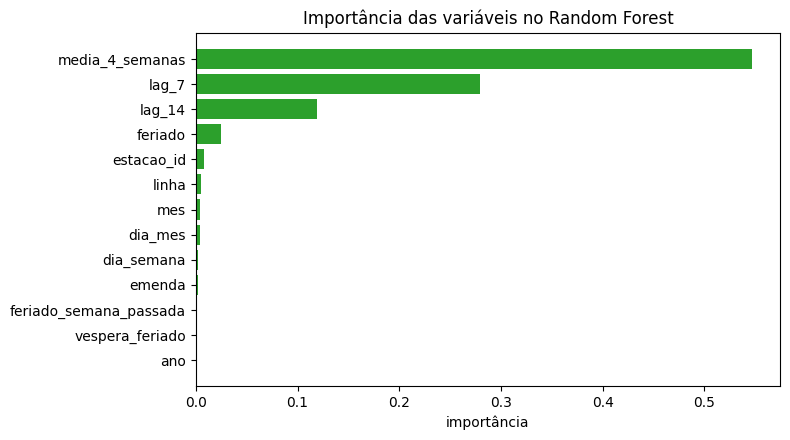

media_4_semanas           0.547
lag_7                     0.279
lag_14                    0.120
feriado                   0.025
estacao_id                0.008
linha                     0.005
mes                       0.005
dia_mes                   0.004
dia_semana                0.002
emenda                    0.002
feriado_semana_passada    0.001
vespera_feriado           0.001
ano                       0.001
dtype: float64

In [18]:
importancias = pd.Series(modelo.feature_importances_, index=features).sort_values()

plt.figure(figsize=(8, 4.5))
plt.barh(importancias.index, importancias.values, color="tab:green")
plt.title("Importância das variáveis no Random Forest")
plt.xlabel("importância")
plt.tight_layout()
plt.show()
importancias.sort_values(ascending=False).round(3)

O histórico recente da estação (`media_4_semanas`, `lag_7` e `lag_14`) é o que mais pesa: ele já carrega o "tamanho" de cada estação e também o dia da semana (porque os lags são sempre do mesmo dia da semana). Por isso `dia_semana` e `estacao_id` aparecem com importância baixa: a informação deles já está dentro dos lags. Depois vem o `feriado`, que é o que explica as grandes quedas. As outras variáveis de calendário ajudam pouco, mas ajustam casos específicos como emendas.

### 7.3 Onde o modelo erra mais

In [19]:
teste_res = teste.copy()
teste_res["previsto"] = prev_teste
teste_res["erro_abs"] = (teste_res["entradas"] - teste_res["previsto"]).abs()
teste_res["erro_pct"] = teste_res["erro_abs"] / teste_res["entradas"] * 100

print("Erro % médio em dias normais:", round(teste_res.loc[teste_res["feriado"] == 0, "erro_pct"].mean(), 1))
print("Erro % médio em feriados:   ", round(teste_res.loc[teste_res["feriado"] == 1, "erro_pct"].mean(), 1))
print()
print("Dias de 2026 com maior erro médio (todas as estações):")
erro_dia = teste_res.groupby("data")["erro_pct"].mean().sort_values(ascending=False).head(8)
erro_dia.round(1)

Erro % médio em dias normais: 5.9
Erro % médio em feriados:    14.6

Dias de 2026 com maior erro médio (todas as estações):


data
2026-01-02    59.1
2026-06-29    35.8
2026-01-03    27.5
2026-04-04    25.7
2026-01-04    25.4
2026-04-20    21.4
2026-02-08    21.4
2026-01-01    21.2
Name: erro_pct, dtype: float64

O erro em feriados (~15%) é mais que o dobro do erro em dias normais (~6%). Os piores dias são o começo de janeiro (recesso de fim de ano, quando muita gente ainda está de férias), dias em torno de feriados e alguns dias atípicos que nenhuma variável do modelo explica (eventos, greves, falhas na operação etc.). Para um aplicativo real, esses dias poderiam ser marcados com um aviso de que a previsão é menos confiável.

## 8. Leitura para o cidadão: nível de lotação

Um número como "47,3 mil entradas" não diz muito para quem vai pegar o metrô. Então transformamos a previsão em um **nível de lotação** comparando com o normal da própria estação:

- **Tranquilo:** abaixo de 80% da média da estação em dias úteis (calculada só com os dados de treino).
- **Normal:** entre 80% e 110%.
- **Cheio:** acima de 110%.

Depois verificamos se o nível previsto bate com o nível real em 2026.

O nível de lotação previsto acertou o nível real em 89.2% dos casos de 2026.


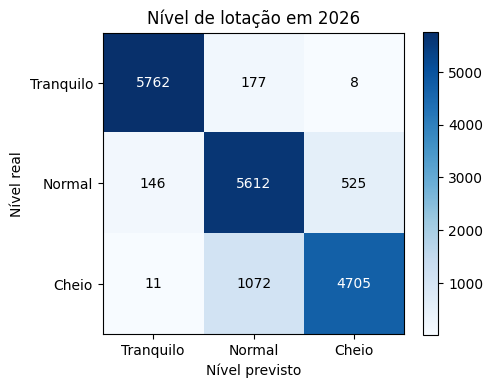

In [20]:
media_util = (treino[(treino["dia_semana"] < 5) & (treino["feriado"] == 0)]
              .groupby("chave")["entradas"].mean())

def nivel(valor, chave):
    razao = valor / chave.map(media_util)
    return pd.cut(razao, bins=[0, 0.8, 1.1, np.inf], labels=["Tranquilo", "Normal", "Cheio"])

teste_res["nivel_real"] = nivel(teste_res["entradas"], teste_res["chave"])
teste_res["nivel_previsto"] = nivel(teste_res["previsto"], teste_res["chave"])
niveis = teste_res.dropna(subset=["nivel_real", "nivel_previsto"])

acerto = (niveis["nivel_real"] == niveis["nivel_previsto"]).mean()
print(f"O nível de lotação previsto acertou o nível real em {acerto:.1%} dos casos de 2026.")

ordem_niveis = ["Tranquilo", "Normal", "Cheio"]
cm = confusion_matrix(niveis["nivel_real"], niveis["nivel_previsto"], labels=ordem_niveis)

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues")
for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xticks(range(3), ordem_niveis)
plt.yticks(range(3), ordem_niveis)
plt.xlabel("Nível previsto")
plt.ylabel("Nível real")
plt.title("Nível de lotação em 2026")
plt.colorbar()
plt.tight_layout()
plt.show()

In [21]:
# Exemplo do que o app mostraria: estação Sé (Linha 1) na semana do feriado de Corpus Christi (04/06/2026)
semana = teste_res[(teste_res["estacao"] == "Sé") & (teste_res["linha"] == 1)
                   & (teste_res["data"].between("2026-06-01", "2026-06-07"))].copy()
semana["dia"] = semana["data"].dt.dayofweek.map(dict(enumerate(nomes_dias)))
semana["% do normal"] = (semana["previsto"] / semana["chave"].map(media_util) * 100).round(0)
semana[["data", "dia", "feriado", "emenda", "previsto", "entradas", "% do normal",
        "nivel_previsto", "nivel_real"]].round(1)

,data,dia,feriado,emenda,previsto,entradas,% do normal,nivel_previsto,nivel_real
105320,2026-06-01,Seg,0,0,14.7,15.5,103.0,Normal,Normal
105373,2026-06-02,Ter,0,0,15.4,16.1,108.0,Normal,Cheio
105452,2026-06-03,Qua,0,0,16.0,16.4,112.0,Cheio,Cheio
105518,2026-06-04,Qui,1,0,5.4,4.7,38.0,Tranquilo,Tranquilo
105584,2026-06-05,Sex,0,1,11.5,13.0,80.0,Normal,Normal
105650,2026-06-06,Sáb,0,0,10.0,9.9,70.0,Tranquilo,Tranquilo
105715,2026-06-07,Dom,0,0,3.9,4.8,27.0,Tranquilo,Tranquilo


Na semana de Corpus Christi o modelo previu corretamente que a Sé ficaria bem mais vazia no feriado (quinta) e no fim de semana, e um pouco abaixo do normal na sexta de emenda. O único erro de nível da semana foi na terça: o modelo previu 108% do normal ("Normal") e o real foi um pouco acima de 110% ("Cheio"). A maior parte dos erros de nível é assim, com o valor real perto do limite entre duas faixas, o que é uma diferença pequena na prática.

Com isso o modelo vira algo útil no dia a dia: o aplicativo da nossa CitizenTech pode mostrar, para cada estação, se o dia deve ser **tranquilo, normal ou cheio**, e o cidadão consegue decidir se vale sair mais cedo, mudar de estação de embarque ou escolher outro horário.

## 9. Conclusão

- **Pergunta:** dá para prever quantas pessoas vão entrar em cada estação do Metrô SP em um dia? **Sim.** Com dados públicos do próprio Metrô, o Random Forest previu as entradas de 2026 (período que ele nunca viu) com R² de ~0,99 e erro médio de ~1,4 mil passageiros por estação por dia (~6%), menos da metade do erro de simplesmente repetir a semana anterior.
- **Hiperparâmetros:** testamos 12 combinações de `n_estimators`, `max_depth` e `min_samples_leaf` com validação cruzada temporal só no treino. Árvores rasas (`max_depth=8`) tiveram underfitting. Árvores profundas com folhas pequenas tiveram o menor erro de validação, mesmo com sinais de overfitting.
- **Overfitting:** o erro no treino é cerca de 3 vezes menor que no teste, então o modelo decora parte do treino. Mas o erro no teste ficou parecido com o da validação cruzada e bem abaixo da linha de base, então ele continua generalizando bem.
- **Para o cidadão:** transformando a previsão em níveis (tranquilo, normal, cheio), o modelo acertou o nível em cerca de 89% dos casos de 2026. Isso permite avisar quem depende do metrô sobre dias de maior lotação, principalmente em feriados e emendas, que são justamente os dias em que a rotina muda.
- **Limitações:** os dados são **totais por dia**, então o modelo não sabe o horário de pico dentro do dia. Também não conhece eventos (shows, jogos, greves, falhas), que causam os maiores erros. Um próximo passo seria juntar dados de eventos e de clima (INMET) e, se o Metrô publicar, dados por faixa horária.